In [ ]:
import datetime
import json
import platform
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from PIL import Image
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

print("TensorFlow version:", tf.__version__, "| Keras:", keras.__version__, "| Python:", platform.python_version())
print("Devices:", tf.config.list_physical_devices())

SEED = 42
keras.utils.set_random_seed(SEED)

# Models go to models/cnn/
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
EXPORT_ROOT = PROJECT_ROOT / "models" / "cnn"
EXPORT_ROOT.mkdir(parents=True, exist_ok=True)
print("Models will be saved in:", EXPORT_ROOT)

CLASS_NAMES = ["airplane", "automobile", "bird", "cat", "deer",
               "dog", "frog", "horse", "ship", "truck"]
NUM_CLASSES = len(CLASS_NAMES)
FEATURE_LAYER = "features"   # name of the layer we extract feature vectors from (Set 8.3)

TensorFlow version: 2.21.0 | Keras: 3.15.1 | Python: 3.11.18
Devices: [PhysicalDevice(name='/physical_device:CPU:0', device_type='CPU')]
Models will be saved in: /Users/luisdavidantonio/Desktop/MAI/2-CV/CV-MAI-2026-27-ForensicsApp/models/cnn


# 2. Data

170498071/170498071 ━━━━━━━━━━━━━━━━━━━━ 481s 3us/step
train: (45000, 32, 32, 3) (45000,)
val:   (5000, 32, 32, 3) (5000,)
test:  (10000, 32, 32, 3) (10000,)
dtype: uint8 | pixel range: 0 - 255


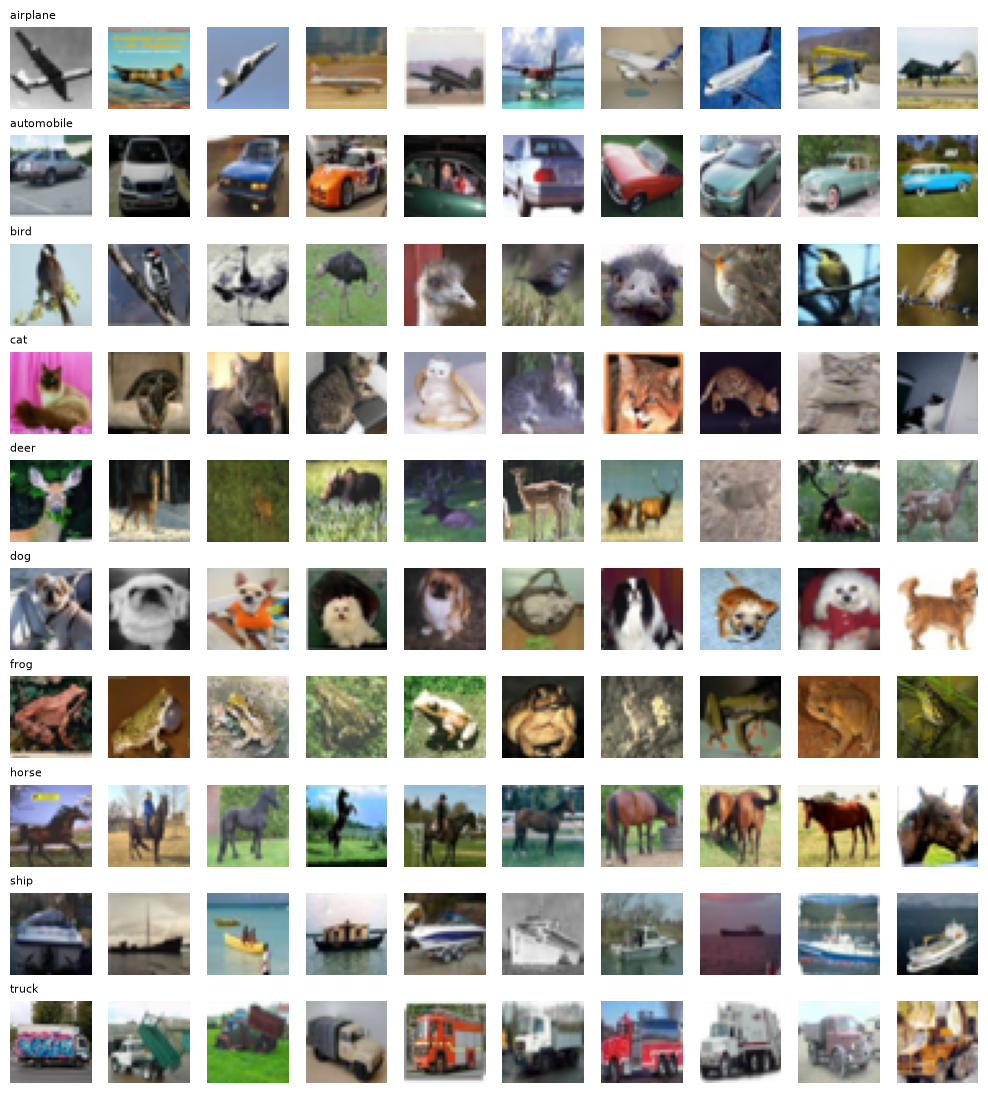

In [ ]:
(x_train_full, y_train_full), (x_test, y_test) = keras.datasets.cifar10.load_data()

# Keras gives labels with shape (N, 1); flatten them to (N,) integers
y_train_full = y_train_full.flatten().astype("int64")
y_test = y_test.flatten().astype("int64")

# Seeded split of the official 50k training set: 45k train / 5k validation
VAL_SIZE = 5000
rng = np.random.default_rng(SEED)
perm = rng.permutation(len(x_train_full))
val_idx, train_idx = perm[:VAL_SIZE], perm[VAL_SIZE:]

x_train, y_train = x_train_full[train_idx], y_train_full[train_idx]
x_val, y_val = x_train_full[val_idx], y_train_full[val_idx]

print("train:", x_train.shape, y_train.shape)
print("val:  ", x_val.shape, y_val.shape)
print("test: ", x_test.shape, y_test.shape)
print("dtype:", x_train.dtype, "| pixel range:", x_train.min(), "-", x_train.max())

# 10x10 grid: one row per class, 10 examples each
fig, axes = plt.subplots(NUM_CLASSES, 10, figsize=(10, 11))
for c in range(NUM_CLASSES):
    idx = np.where(y_train == c)[0][:10]
    for j, i in enumerate(idx):
        ax = axes[c, j]
        ax.imshow(x_train[i])
        ax.axis("off")
        if j == 0:
            ax.set_title(CLASS_NAMES[c], fontsize=8, loc="left")
plt.tight_layout()
plt.show()

# 3. Preprocessing & tf.data

In [ ]:
AUTOTUNE = tf.data.AUTOTUNE

def preprocess_images(images, input_size, scaling):
    """uint8 RGB batch -> float32 batch, resized and scaled.

    This exact recipe is written into the passport, so the app can
    reproduce it with PIL/numpy at prediction time.
    """
    x = tf.cast(images, tf.float32)
    if tuple(x.shape[1:3]) != tuple(input_size):
        x = tf.image.resize(x, input_size, method="bilinear")
    if scaling == "0_1":
        x = x / 255.0
    elif scaling == "-1_1":
        x = x / 127.5 - 1.0
    else:
        raise ValueError(f"Unknown scaling: {scaling}")
    return x


def make_dataset(x, y, input_size, scaling, batch_size, shuffle):
    ds = tf.data.Dataset.from_tensor_slices((x, y))
    if shuffle:
        ds = ds.shuffle(len(x), seed=SEED, reshuffle_each_iteration=True)
    ds = ds.batch(batch_size)
    ds = ds.map(lambda xb, yb: (preprocess_images(xb, input_size, scaling), yb),
                num_parallel_calls=AUTOTUNE)
    return ds.prefetch(AUTOTUNE)


def stratified_subset(x, y, per_class, seed=SEED):
    """Pick `per_class` random images from every class (balanced subset)."""
    rng = np.random.default_rng(seed)
    idx = np.concatenate([
        rng.choice(np.where(y == c)[0], per_class, replace=False)
        for c in range(NUM_CLASSES)
    ])
    rng.shuffle(idx)
    return x[idx], y[idx]


def class_counts(y):
    return dict(zip(CLASS_NAMES, np.bincount(y, minlength=NUM_CLASSES).tolist()))


# Sanity check: one small batch for each model's preprocessing
print("train images per class:", class_counts(y_train))
for size, scaling in [((32, 32), "0_1"), ((128, 128), "-1_1")]:
    xb, yb = next(iter(make_dataset(x_train[:8], y_train[:8], size, scaling, 8, False)))
    print(f"{size} {scaling}: batch {tuple(xb.shape)} {xb.dtype.name} "
          f"min={float(tf.reduce_min(xb)):.3f} max={float(tf.reduce_max(xb)):.3f} "
          f"labels {yb.numpy()}")

train images per class: {'airplane': 4527, 'automobile': 4458, 'bird': 4465, 'cat': 4518, 'deer': 4477, 'dog': 4527, 'frog': 4498, 'horse': 4531, 'ship': 4482, 'truck': 4517}
(32, 32) 0_1: batch (8, 32, 32, 3) float32 min=0.000 max=1.000 labels [7 0 9 8 2 3 1 8]
(128, 128) -1_1: batch (8, 128, 128, 3) float32 min=-0.998 max=1.000 labels [7 0 9 8 2 3 1 8]


# 4. Passport & Export

In [ ]:
import re
import tempfile


def preprocessing_info(input_size, scaling):
    """Preprocessing info so the Forensics app can reproduce it with PIL/numpy."""
    h, w = input_size
    formula = {"0_1": "x / 255.0", "-1_1": "x / 127.5 - 1.0"}[scaling]
    return {
        "color_mode": "RGB",
        "input_size": [h, w],
        "input_shape": [h, w, 3],
        "resize_method": "bilinear",
        "keep_aspect_ratio": False,
        "scaling": scaling,
        "formula": formula,
        "dtype": "float32",
        "steps": [
            "Convert the image to RGB (drop alpha, expand grayscale).",
            f"Resize to width={w}, height={h} with bilinear interpolation "
            "(aspect ratio is not preserved).",
            "Convert to a float32 array of shape (h, w, 3).",
            f"Scale pixel values: {formula}.",
            f"Add a batch dimension -> (1, {h}, {w}, 3).",
        ],
    }


def history_dict(histories):
    """Merge one or more Keras History objects into a single dict of float lists."""
    merged = {}
    for h in histories:
        for key, values in h.history.items():
            merged.setdefault(key, []).extend(float(v) for v in values)
    return merged


def model_summary_text(model):
    """model.summary() captured as a string (instead of printed)."""
    lines = []
    model.summary(print_fn=lambda line, **kwargs: lines.append(line))
    return re.sub(r"\x1b\[[0-9;]*m", "", "\n".join(lines))  # strip terminal colours


def count_params(model):
    trainable = int(sum(np.prod(w.shape) for w in model.trainable_weights))
    non_trainable = int(sum(np.prod(w.shape) for w in model.non_trainable_weights))
    return {"total": trainable + non_trainable,
            "trainable": trainable,
            "non_trainable": non_trainable}


def plot_history(history, title, phase_boundaries=None, save_path=None):
    """Loss and accuracy per epoch, train vs validation."""
    epochs = np.arange(1, len(history["loss"]) + 1)
    fig, axes = plt.subplots(1, 2, figsize=(11, 4))
    for ax, metric in zip(axes, ["loss", "accuracy"]):
        ax.plot(epochs, history[metric], marker="o", ms=3, label=f"train {metric}")
        if f"val_{metric}" in history:
            ax.plot(epochs, history[f"val_{metric}"], marker="o", ms=3,
                    label=f"val {metric}")
        for b in phase_boundaries or []:   # dashed line where fine-tuning starts
            ax.axvline(b + 0.5, color="gray", ls="--", lw=1)
        ax.set_xlabel("epoch")
        ax.set_title(metric)
        ax.grid(alpha=0.3)
        ax.legend()
    fig.suptitle(title)
    fig.tight_layout()
    if save_path is not None:
        fig.savefig(save_path, dpi=120)
    return fig


def export_model(model, *, model_name, display_name, description, architecture,
                 input_size, scaling, train_labels, val_labels, validation_split,
                 training, histories, export_root=EXPORT_ROOT, eval_batch_size=128,
                 show=True):
    out_dir = Path(export_root) / model_name
    out_dir.mkdir(parents=True, exist_ok=True)

    # 1) Test set, preprocessed exactly like in training -- and NOT shuffled,
    #    so features[i] / predictions[i] belong to y_test[i]
    test_ds = make_dataset(x_test, y_test, input_size, scaling, eval_batch_size,
                           shuffle=False)

    # 2) A second "view" of the same network with two outputs:
    #    the feature layer and the final probabilities -> one pass gives both
    feature_model = keras.Model(
        inputs=model.inputs,
        outputs=[model.get_layer(FEATURE_LAYER).output, model.outputs[0]],
    )
    features, probs = feature_model.predict(test_ds, verbose=0)
    predictions = probs.argmax(axis=1).astype("int64")

    # 3) Evaluation: accuracy, loss, confusion matrix, per-class accuracy
    test_acc = float((predictions == y_test).mean())
    test_loss = float(-np.mean(np.log(probs[np.arange(len(y_test)), y_test] + 1e-7)))
    cm = np.zeros((NUM_CLASSES, NUM_CLASSES), dtype=np.int64)
    np.add.at(cm, (y_test, predictions), 1)          # rows = true, cols = predicted
    per_class_acc = cm.diagonal() / cm.sum(axis=1)

    # 4) Files
    model.save(out_dir / "model.keras")
    np.savez_compressed(
        out_dir / "features_test.npz",
        features=features.astype("float32"),
        labels=y_test.astype("int64"),
        predictions=predictions,
        class_names=np.array(CLASS_NAMES),
        layer_name=np.array(FEATURE_LAYER),
        model_name=np.array(model_name),
        split=np.array("test"),
    )
    history = history_dict(histories)
    boundaries = [int(b) for b in np.cumsum([len(h.epoch) for h in histories])[:-1]]
    fig = plot_history(history, display_name, boundaries,
                       out_dir / "training_curves.png")
    plt.show() if show else plt.close(fig)

    # 5) The passport
    passport = {
        "passport_version": 1,
        "model_name": model_name,
        "display_name": display_name,
        "task": "image_classification",
        "description": description,
        "architecture": {
            **architecture,
            "parameters": count_params(model),
            "summary": model_summary_text(model),
        },
        "dataset": {
            "name": "CIFAR-10",
            "source": "keras.datasets.cifar10 (https://www.cs.toronto.edu/~kriz/cifar.html)",
            "original_image_size": [32, 32],
            "num_classes": NUM_CLASSES,
            "sample_sizes": {"train": int(len(train_labels)),
                             "validation": int(len(val_labels)),
                             "test": int(len(y_test))},
            "train_samples_per_class": class_counts(train_labels),
            "validation_samples_per_class": class_counts(val_labels),
            "validation_split": validation_split,
        },
        "class_names": CLASS_NAMES,
        "preprocessing": preprocessing_info(input_size, scaling),
        "training": {
            **training,
            "epochs_run": len(history["loss"]),
            "phase_boundaries": boundaries,
            "history": history,
        },
        "evaluation": {
            "split": "test",
            "num_samples": int(len(y_test)),
            "test_loss": test_loss,
            "test_accuracy": test_acc,
            "per_class_accuracy": dict(zip(CLASS_NAMES,
                                           per_class_acc.round(4).tolist())),
            "confusion_matrix": cm.tolist(),
        },
        "feature_extraction": {
            "layer": FEATURE_LAYER,
            "dimension": int(features.shape[1]),
            "split": "test",
            "num_samples": int(features.shape[0]),
            "file": "features_test.npz",
        },
        "files": {"model": "model.keras", "passport": "passport.json",
                  "features": "features_test.npz",
                  "training_curves": "training_curves.png"},
        "environment": {"tensorflow": tf.__version__, "keras": keras.__version__,
                        "python": platform.python_version()},
        "created_utc": datetime.datetime.now(datetime.timezone.utc)
                               .isoformat(timespec="seconds"),
    }
    with open(out_dir / "passport.json", "w", encoding="utf-8") as f:
        json.dump(passport, f, indent=2, ensure_ascii=False)

    print(f"Exported '{model_name}' to {out_dir}")
    print(f"  test accuracy {test_acc:.4f} | test loss {test_loss:.4f} | "
          f"features {features.shape}")
    return passport


# ---- Smoke test: tiny model, 1 epoch, exported to a temporary folder ----
tiny = keras.Sequential([
    keras.Input(shape=(32, 32, 3)),
    layers.Conv2D(8, 3, activation="relu"),
    layers.GlobalAveragePooling2D(),
    layers.Dense(16, activation="relu", name=FEATURE_LAYER),
    layers.Dense(NUM_CLASSES, activation="softmax", name="predictions"),
], name="smoke_test")
tiny.compile(optimizer="adam", loss="sparse_categorical_crossentropy",
             metrics=["accuracy"])
h = tiny.fit(make_dataset(x_train[:1000], y_train[:1000], (32, 32), "0_1", 64, True),
             validation_data=make_dataset(x_val[:200], y_val[:200], (32, 32), "0_1",
                                          64, False),
             epochs=1, verbose=0)

with tempfile.TemporaryDirectory(ignore_cleanup_errors=True) as tmp:
    p = export_model(tiny, model_name="smoke_test", display_name="Smoke test",
                     description="Throw-away model to test the export helpers.",
                     architecture={"type": "tiny CNN"}, input_size=(32, 32),
                     scaling="0_1", train_labels=y_train[:1000],
                     val_labels=y_val[:200], validation_split="first 200 val images",
                     training={"optimizer": "adam"}, histories=[h],
                     export_root=tmp, show=False)
    folder = Path(tmp) / "smoke_test"
    print("files:", sorted(f.name for f in folder.iterdir()))
    with np.load(folder / "features_test.npz") as npz:
        print("npz:", {k: npz[k].shape for k in npz.files})
    reloaded = keras.models.load_model(folder / "model.keras")
    print("reloaded:", reloaded.name, "| passport keys:", list(p))

/Users/luisdavidantonio/Desktop/MAI/2-CV/CV-MAI-2026-27-ForensicsApp/.venv/lib/python3.11/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


Exported 'smoke_test' to /var/folders/xf/93q_732s7qj6pw7d65d4qynr0000gn/T/tmpt2ubpiu3/smoke_test
  test accuracy 0.1039 | test loss 2.2976 | features (10000, 16)
files: ['features_test.npz', 'model.keras', 'passport.json', 'training_curves.png']
npz: {'features': (10000, 16), 'labels': (10000,), 'predictions': (10000,), 'class_names': (10,), 'layer_name': (), 'model_name': (), 'split': ()}
reloaded: smoke_test | passport keys: ['passport_version', 'model_name', 'display_name', 'task', 'description', 'architecture', 'dataset', 'class_names', 'preprocessing', 'training', 'evaluation', 'feature_extraction', 'files', 'environment', 'created_utc']


# 5a: Build the small CNN

In [ ]:
keras.backend.clear_session() 
keras.utils.set_random_seed(SEED)

SMALL_NAME = "cifar10_small_cnn"
SMALL_SIZE = (32, 32)
SMALL_SCALING = "0_1"
SMALL_BATCH = 64
SMALL_EPOCHS = 60
SMALL_LR = 1e-3


def conv_block(filters, dropout, block):
    """[Conv3x3 -> BatchNorm -> ReLU] x 2 -> MaxPool 2x2 -> Dropout"""
    return [
        layers.Conv2D(filters, 3, padding="same", use_bias=False,
                      name=f"block{block}_conv1"),
        layers.BatchNormalization(name=f"block{block}_bn1"),
        layers.Activation("relu", name=f"block{block}_relu1"),
        layers.Conv2D(filters, 3, padding="same", use_bias=False,
                      name=f"block{block}_conv2"),
        layers.BatchNormalization(name=f"block{block}_bn2"),
        layers.Activation("relu", name=f"block{block}_relu2"),
        layers.MaxPooling2D(2, name=f"block{block}_pool"),
        layers.Dropout(dropout, name=f"block{block}_dropout"),
    ]


small_cnn = keras.Sequential([
    keras.Input(shape=(*SMALL_SIZE, 3), name="image"),
    # Data augmentation: active only during training, does nothing at prediction time
    layers.RandomFlip("horizontal", seed=SEED, name="aug_flip"),
    layers.RandomTranslation(0.1, 0.1, fill_mode="reflect", seed=SEED,
                             name="aug_translate"),
    # Feature extractor: 32x32 -> 16x16 -> 8x8 -> 4x4
    *conv_block(32, 0.2, block=1),
    *conv_block(64, 0.3, block=2),
    *conv_block(128, 0.4, block=3),
    # Classifier head
    layers.Flatten(name="flatten"),                                # 4*4*128 = 2048
    layers.Dense(256, activation="relu", name=FEATURE_LAYER),      # <- 8.3 features
    layers.Dropout(0.5, name="head_dropout"),
    layers.Dense(NUM_CLASSES, activation="softmax", name="predictions"),
], name=SMALL_NAME)

small_cnn.compile(
    optimizer=keras.optimizers.Adam(learning_rate=SMALL_LR),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)
small_cnn.summary()

Model: "cifar10_small_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ aug_flip (RandomFlip)           │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ aug_translate                   │ (None, 32, 32, 3)      │             0 │
│ (RandomTranslation)             │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv1 (Conv2D)           │ (None, 32, 32, 32)     │           864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_bn1 (BatchNormalization) │ (None, 32, 32, 32)     │           128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_relu1 (Activation)       │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv2 (Conv2D)           │ (None, 32, 32, 32)     │         9,216 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_bn2 (BatchNormalization) │ (None, 32, 32, 32)     │           128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_relu2 (Activation)       │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_pool (MaxPooling2D)      │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_dropout (Dropout)        │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv1 (Conv2D)           │ (None, 16, 16, 64)     │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_bn1 (BatchNormalization) │ (None, 16, 16, 64)     │           256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_relu1 (Activation)       │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv2 (Conv2D)           │ (None, 16, 16, 64)     │        36,864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_bn2 (BatchNormalization) │ (None, 16, 16, 64)     │           256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_relu2 (Activation)       │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_pool (MaxPooling2D)      │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_dropout (Dropout)        │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv1 (Conv2D)           │ (None, 8, 8, 128)      │        73,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_bn1 (BatchNormalization) │ (None, 8, 8, 128)      │           512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_relu1 (Activation)       │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv2 (Conv2D)           │ (None, 8, 8, 128)      │       147,456 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_bn2 (BatchNormalization) │ (None, 8, 8, 128)      │           512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_relu2 (Activation)       │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼─────────────

 Total params: 815,466 (3.11 MB)

 Trainable params: 814,570 (3.11 MB)

 Non-trainable params: 896 (3.50 KB)

# 5b: Train

In [ ]:
train_ds = make_dataset(x_train, y_train, SMALL_SIZE, SMALL_SCALING, SMALL_BATCH,
                        shuffle=True)
val_ds = make_dataset(x_val, y_val, SMALL_SIZE, SMALL_SCALING, SMALL_BATCH,
                      shuffle=False)

small_callbacks = [
    # Stop when val accuracy hasn't improved for 5 epochs; keep the best weights
    keras.callbacks.EarlyStopping(monitor="val_accuracy", patience=5,
                                  restore_best_weights=True, verbose=1),
    # Halve the learning rate when val loss stalls for 3 epochs
    keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=3,
                                      verbose=1),
]

small_history = small_cnn.fit(
    train_ds,
    validation_data=val_ds,
    epochs=SMALL_EPOCHS,
    callbacks=small_callbacks,
    shuffle=False,      # tf.data already shuffles -> silences the warning
    verbose=1,
)
best_epoch = int(np.argmax(small_history.history["val_accuracy"])) + 1
print(f"Best epoch: {best_epoch} | best val_accuracy: "
      f"{max(small_history.history['val_accuracy']):.4f}")

Epoch 1/60
704/704 ━━━━━━━━━━━━━━━━━━━━ 23s 31ms/step - accuracy: 0.3026 - loss: 1.8483 - val_accuracy: 0.3342 - val_loss: 1.8509 - learning_rate: 0.0010
Epoch 2/60
704/704 ━━━━━━━━━━━━━━━━━━━━ 23s 32ms/step - accuracy: 0.4358 - loss: 1.5248 - val_accuracy: 0.4956 - val_loss: 1.4025 - learning_rate: 0.0010
Epoch 3/60
704/704 ━━━━━━━━━━━━━━━━━━━━ 24s 34ms/step - accuracy: 0.5110 - loss: 1.3465 - val_accuracy: 0.5712 - val_loss: 1.1476 - learning_rate: 0.0010
Epoch 4/60
704/704 ━━━━━━━━━━━━━━━━━━━━ 24s 34ms/step - accuracy: 0.5658 - loss: 1.2209 - val_accuracy: 0.5988 - val_loss: 1.1654 - learning_rate: 0.0010
Epoch 5/60
704/704 ━━━━━━━━━━━━━━━━━━━━ 24s 34ms/step - accuracy: 0.6074 - loss: 1.1219 - val_accuracy: 0.6788 - val_loss: 0.8842 - learning_rate: 0.0010
Epoch 6/60
704/704 ━━━━━━━━━━━━━━━━━━━━ 24s 34ms/step - accuracy: 0.6351 - loss: 1.0462 - val_accuracy: 0.5988 - val_loss: 1.2124 - learning_rate: 0.0010
Epoch 7/60
704/704 ━━━━━━━━━━━━━━━━━━━━ 25s 35ms/step - accuracy: 0.6622 - l

# 5c. Passport + export

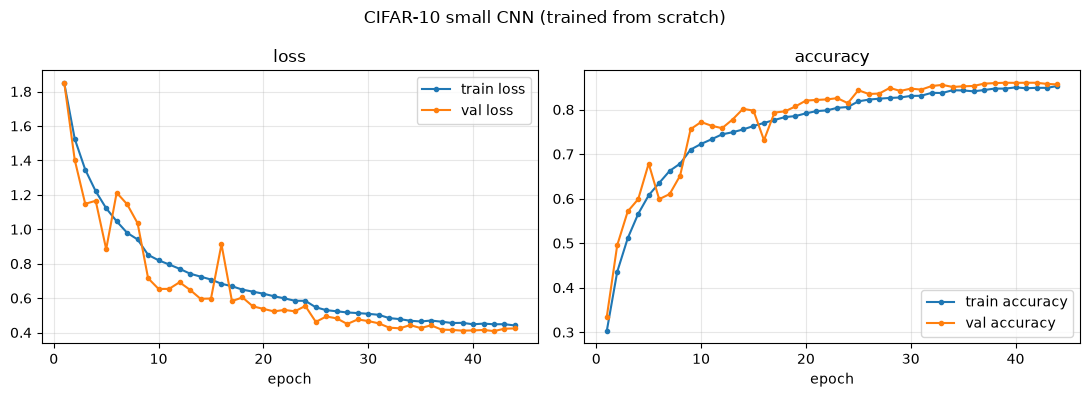

Exported 'cifar10_small_cnn' to /Users/luisdavidantonio/Desktop/MAI/2-CV/CV-MAI-2026-27-ForensicsApp/models/cnn/cifar10_small_cnn
  test accuracy 0.8576 | test loss 0.4360 | features (10000, 256)
Per-class test accuracy: {'airplane': 0.9, 'automobile': 0.954, 'bird': 0.772, 'cat': 0.676, 'deer': 0.84, 'dog': 0.764, 'frog': 0.956, 'horse': 0.866, 'ship': 0.925, 'truck': 0.923}


In [12]:
# --- Step 5c: Passport + export ---
small_passport = export_model(
    small_cnn,
    model_name=SMALL_NAME,
    display_name="CIFAR-10 small CNN (trained from scratch)",
    description=("Compact 3-block convolutional network trained from scratch on "
                 "CIFAR-10 (32x32 RGB, 10 classes)."),
    architecture={
        "type": "Sequential CNN trained from scratch",
        "input_shape": [*SMALL_SIZE, 3],
        "blocks": "3 x [Conv3x3-BN-ReLU x2, MaxPool2x2, Dropout 0.2/0.3/0.4], "
                  "32/64/128 filters",
        "head": "Flatten -> Dense 256 ReLU ('features') -> Dropout 0.5 -> "
                "Dense 10 softmax ('predictions')",
    },
    input_size=SMALL_SIZE,
    scaling=SMALL_SCALING,
    train_labels=y_train,
    val_labels=y_val,
    validation_split=(f"{VAL_SIZE} images held out at random (seed {SEED}) from the "
                      "official 50k CIFAR-10 training set"),
    training={
        "optimizer": "Adam",
        "learning_rate": SMALL_LR,
        "loss": "sparse_categorical_crossentropy",
        "batch_size": SMALL_BATCH,
        "max_epochs": SMALL_EPOCHS,
        "best_epoch": best_epoch,
        "augmentation": ["RandomFlip(horizontal)",
                         "RandomTranslation(0.1, 0.1, fill_mode=reflect)"],
        "callbacks": [
            "EarlyStopping(monitor=val_accuracy, patience=5, restore_best_weights=True)",
            "ReduceLROnPlateau(monitor=val_loss, factor=0.5, patience=3)",
        ],
    },
    histories=[small_history],
)
print("Per-class test accuracy:", small_passport["evaluation"]["per_class_accuracy"])

# 6a: InceptionV3 transfer model

In [ ]:
INC_NAME = "cifar10_inceptionv3"
INC_SIZE = (128, 128)
INC_SCALING = "-1_1"            # InceptionV3's ImageNet preprocessing
INC_BATCH = 32
INC_PER_CLASS_TRAIN = 4000
INC_PER_CLASS_VAL = 400
INC_EPOCHS_HEAD = 5
INC_EPOCHS_FINE = 5
INC_LR_HEAD = 1e-3
INC_LR_FINE = 1e-4
INC_UNFREEZE_FROM = "mixed9"

# Balanced subsets (CPU budget): 10k train, 2k validation
x_train_inc, y_train_inc = stratified_subset(x_train, y_train, INC_PER_CLASS_TRAIN)
x_val_inc, y_val_inc = stratified_subset(x_val, y_val, INC_PER_CLASS_VAL)
print("train:", x_train_inc.shape, class_counts(y_train_inc))
print("val:  ", x_val_inc.shape)

train_inc_ds = make_dataset(x_train_inc, y_train_inc, INC_SIZE, INC_SCALING,
                            INC_BATCH, shuffle=True)
val_inc_ds = make_dataset(x_val_inc, y_val_inc, INC_SIZE, INC_SCALING,
                          INC_BATCH, shuffle=False)

# Pretrained base (downloads ~87 MB of ImageNet weights the first time)
base = keras.applications.InceptionV3(include_top=False, weights="imagenet",
                                      input_shape=(*INC_SIZE, 3))
base.trainable = False

inputs = keras.Input(shape=(*INC_SIZE, 3), name="image")
x = layers.RandomFlip("horizontal", seed=SEED, name="aug_flip")(inputs)
x = layers.RandomTranslation(0.1, 0.1, fill_mode="reflect", seed=SEED,
                             name="aug_translate")(x)
x = base(x, training=False)          # BatchNorm inside the base stays in inference mode
x = layers.GlobalAveragePooling2D(name="global_avg_pool")(x)        # (2,2,2048) -> 2048
x = layers.Dense(1024, activation="relu", name=FEATURE_LAYER)(x)   # <- 8.3 features
x = layers.Dropout(0.3, name="head_dropout")(x)
outputs = layers.Dense(NUM_CLASSES, activation="softmax", name="predictions")(x)
inc_model = keras.Model(inputs, outputs, name=INC_NAME)

inc_model.summary()
params_head = count_params(inc_model)
print("Phase 1 parameters:", params_head)

train: (40000, 32, 32, 3) {'airplane': 4000, 'automobile': 4000, 'bird': 4000, 'cat': 4000, 'deer': 4000, 'dog': 4000, 'frog': 4000, 'horse': 4000, 'ship': 4000, 'truck': 4000}
val:   (4000, 32, 32, 3)


Model: "cifar10_inceptionv3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ image (InputLayer)              │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ aug_flip (RandomFlip)           │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ aug_translate                   │ (None, 128, 128, 3)    │             0 │
│ (RandomTranslation)             │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ inception_v3 (Functional)       │ (None, 2, 2, 2048)     │    21,802,784 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_avg_pool                 │ (None, 2048)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ features (Dense)                │ (None, 1024)           │     2,098,176 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ head_dropout (Dropout)          │ (None, 1024)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ predictions (Dense)             │ (None, 10)             │        10,250 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 23,911,210 (91.21 MB)

 Trainable params: 2,108,426 (8.04 MB)

 Non-trainable params: 21,802,784 (83.17 MB)

Phase 1 parameters: {'total': 23911210, 'trainable': 2108426, 'non_trainable': 21802784}


# 6b: Phase 1 -- frozen base, train the new head

In [ ]:
inc_model.compile(optimizer=keras.optimizers.Adam(INC_LR_HEAD),
                  loss="sparse_categorical_crossentropy", metrics=["accuracy"])
inc_hist_head = inc_model.fit(train_inc_ds, validation_data=val_inc_ds,
                              epochs=INC_EPOCHS_HEAD, shuffle=False, verbose=1)

Epoch 1/5
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 80s 63ms/step - accuracy: 0.7018 - loss: 0.9253 - val_accuracy: 0.7782 - val_loss: 0.6535
Epoch 2/5
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 85s 68ms/step - accuracy: 0.7459 - loss: 0.7578 - val_accuracy: 0.7670 - val_loss: 0.6861
Epoch 3/5
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 98s 78ms/step - accuracy: 0.7546 - loss: 0.7231 - val_accuracy: 0.7835 - val_loss: 0.6294
Epoch 4/5
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 103s 82ms/step - accuracy: 0.7586 - loss: 0.7101 - val_accuracy: 0.7908 - val_loss: 0.6011
Epoch 5/5
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 105s 84ms/step - accuracy: 0.7675 - loss: 0.6863 - val_accuracy: 0.7918 - val_loss: 0.6110


# 6c: Phase 2 -- unfreeze from mixed9, fine-tune with a low LR

In [ ]:
base.trainable = True
unfreeze_idx = [l.name for l in base.layers].index(INC_UNFREEZE_FROM)
for layer in base.layers[:unfreeze_idx]:
    layer.trainable = False
print(f"Unfrozen {len(base.layers) - unfreeze_idx} of {len(base.layers)} base layers")

# Changing .trainable only takes effect after compiling again
inc_model.compile(optimizer=keras.optimizers.Adam(INC_LR_FINE),
                  loss="sparse_categorical_crossentropy", metrics=["accuracy"])
params_fine = count_params(inc_model)
print("Phase 2 parameters:", params_fine)

inc_fine_callbacks = [
    keras.callbacks.EarlyStopping(monitor="val_accuracy", patience=2,
                                  restore_best_weights=True, verbose=1),
]
inc_hist_fine = inc_model.fit(train_inc_ds, validation_data=val_inc_ds,
                              initial_epoch=INC_EPOCHS_HEAD,
                              epochs=INC_EPOCHS_HEAD + INC_EPOCHS_FINE,
                              callbacks=inc_fine_callbacks,
                              shuffle=False, verbose=1)


Unfrozen 32 of 311 base layers
Phase 2 parameters: {'total': 23911210, 'trainable': 8181962, 'non_trainable': 15729248}
Epoch 6/10
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 94s 73ms/step - accuracy: 0.7893 - loss: 0.6275 - val_accuracy: 0.8300 - val_loss: 0.4877
Epoch 7/10
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 107s 86ms/step - accuracy: 0.8259 - loss: 0.5122 - val_accuracy: 0.8455 - val_loss: 0.4455
Epoch 8/10
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 124s 99ms/step - accuracy: 0.8467 - loss: 0.4458 - val_accuracy: 0.8585 - val_loss: 0.4334
Epoch 9/10
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 128s 103ms/step - accuracy: 0.8623 - loss: 0.4023 - val_accuracy: 0.8528 - val_loss: 0.4386
Epoch 10/10
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 124s 99ms/step - accuracy: 0.8739 - loss: 0.3681 - val_accuracy: 0.8597 - val_loss: 0.4346
Restoring model weights from the end of the best epoch: 10.


# Step 6d: Passport + export

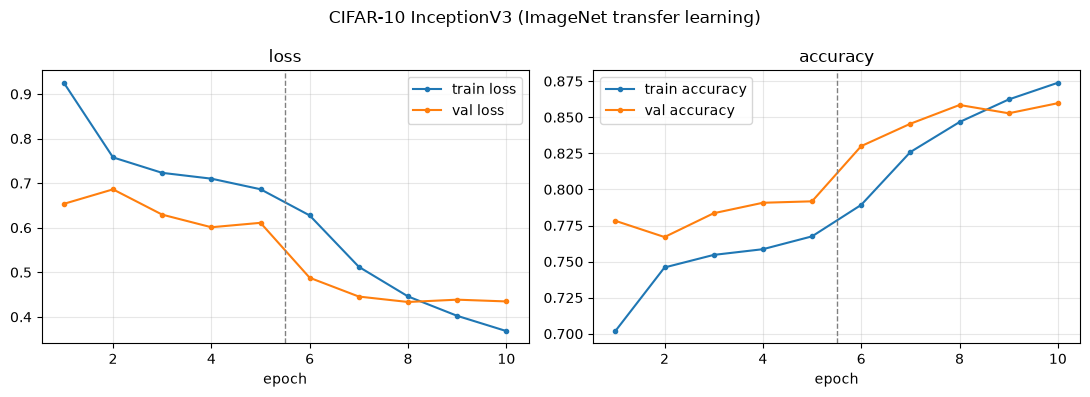

Exported 'cifar10_inceptionv3' to /Users/luisdavidantonio/Desktop/MAI/2-CV/CV-MAI-2026-27-ForensicsApp/models/cnn/cifar10_inceptionv3
  test accuracy 0.8499 | test loss 0.4527 | features (10000, 1024)
Per-class test accuracy: {'airplane': 0.886, 'automobile': 0.898, 'bird': 0.828, 'cat': 0.694, 'deer': 0.816, 'dog': 0.784, 'frog': 0.906, 'horse': 0.861, 'ship': 0.91, 'truck': 0.916}


In [ ]:
inc_passport = export_model(
    inc_model,
    model_name=INC_NAME,
    display_name="CIFAR-10 InceptionV3 (ImageNet transfer learning)",
    description=("ImageNet-pretrained InceptionV3 with a new classification head, "
                 "trained on a stratified CIFAR-10 subset in two phases "
                 "(frozen base, then fine-tuning of the top blocks)."),
    architecture={
        "type": "Transfer learning: InceptionV3 base + new head",
        "input_shape": [*INC_SIZE, 3],
        "base": "keras.applications.InceptionV3(weights='imagenet', include_top=False)",
        "head": "GlobalAveragePooling2D -> Dense 1024 ReLU ('features') -> "
                "Dropout 0.3 -> Dense 10 softmax ('predictions')",
        "fine_tuned_from_layer": INC_UNFREEZE_FROM,
        "base_batchnorm_mode": "inference (base called with training=False)",
    },
    input_size=INC_SIZE,
    scaling=INC_SCALING,
    train_labels=y_train_inc,
    val_labels=y_val_inc,
    validation_split=(f"stratified subset of {INC_PER_CLASS_VAL} images per class "
                      f"from the {VAL_SIZE}-image validation split (seed {SEED})"),
    training={
        "optimizer": "Adam",
        "loss": "sparse_categorical_crossentropy",
        "batch_size": INC_BATCH,
        "augmentation": ["RandomFlip(horizontal)",
                         "RandomTranslation(0.1, 0.1, fill_mode=reflect)"],
        "callbacks": ["phase 2: EarlyStopping(monitor=val_accuracy, patience=2, "
                      "restore_best_weights=True)"],
        "phases": [
            {"name": "head", "base_frozen": True, "learning_rate": INC_LR_HEAD,
             "epochs": INC_EPOCHS_HEAD, "parameters": params_head},
            {"name": "fine_tune", "unfrozen_from": INC_UNFREEZE_FROM,
             "learning_rate": INC_LR_FINE, "epochs": INC_EPOCHS_FINE,
             "parameters": params_fine},
        ],
    },
    histories=[inc_hist_head, inc_hist_fine],
)
print("Per-class test accuracy:", inc_passport["evaluation"]["per_class_accuracy"])

# 6e: Compare the two exported models

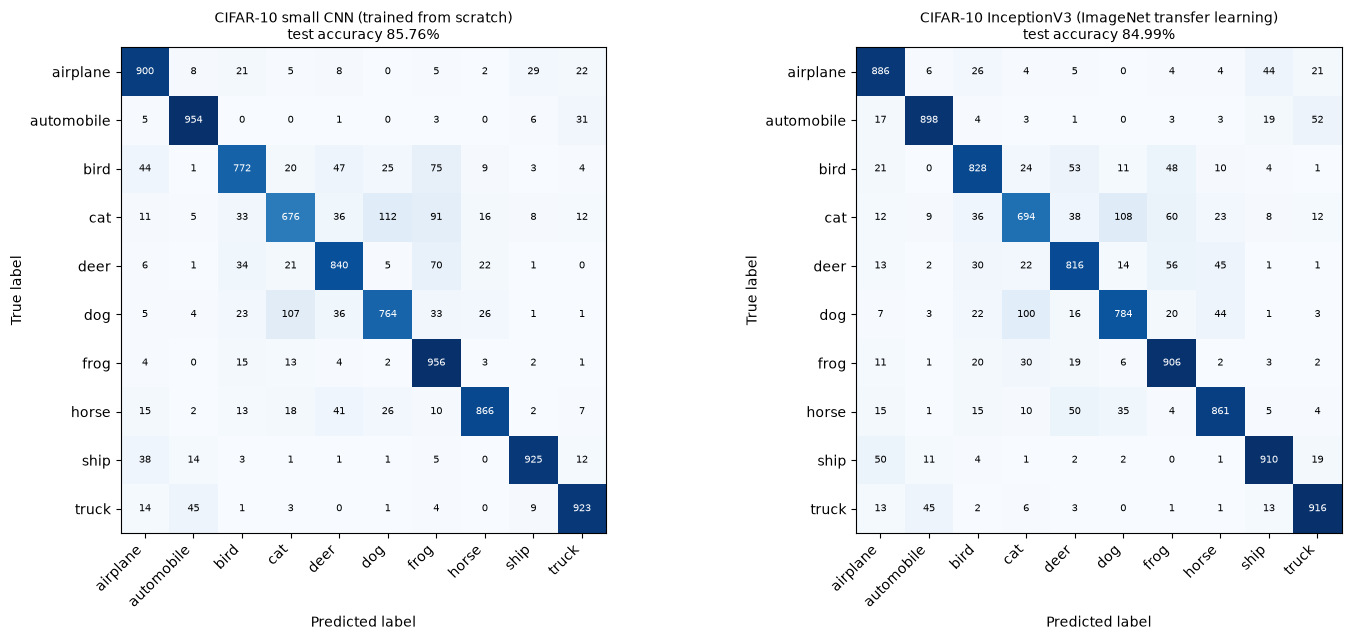

class            cifar10_small_cnn   cifar10_inceptionv3
airplane                     0.900                 0.886
automobile                   0.954                 0.898
bird                         0.772                 0.828
cat                          0.676                 0.694
deer                         0.840                 0.816
dog                          0.764                 0.784
frog                         0.956                 0.906
horse                        0.866                 0.861
ship                         0.925                 0.910
truck                        0.923                 0.916


In [ ]:
def plot_confusion(passport, ax):
    cm = np.array(passport["evaluation"]["confusion_matrix"])
    names = passport["class_names"]
    ax.imshow(cm, cmap="Blues")
    thresh = cm.max() / 2
    for i, j in np.ndindex(cm.shape):
        ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=7,
                color="white" if cm[i, j] > thresh else "black")
    ax.set_xticks(range(len(names)), names, rotation=45, ha="right")
    ax.set_yticks(range(len(names)), names)
    ax.set_xlabel("Predicted label")
    ax.set_ylabel("True label")
    acc = passport["evaluation"]["test_accuracy"]
    ax.set_title(f"{passport['display_name']}\ntest accuracy {acc:.2%}", fontsize=10)

# Read the passports back from disk -- also proves the export is complete
passports = {name: json.loads((EXPORT_ROOT / name / "passport.json")
                              .read_text(encoding="utf-8"))
             for name in [SMALL_NAME, INC_NAME]}

fig, axes = plt.subplots(1, 2, figsize=(15, 6.5))
for ax, p in zip(axes, passports.values()):
    plot_confusion(p, ax)
fig.tight_layout()
plt.show()

# Per-class accuracy side by side
print(f"{'class':<12}" + "".join(f"{n:>22}" for n in passports))
for c in CLASS_NAMES:
    print(f"{c:<12}" + "".join(f"{p['evaluation']['per_class_accuracy'][c]:>22.3f}"
                               for p in passports.values()))

# 7a: Sample images for the app (10 test images per class)

In [ ]:
SAMPLE_DIR = EXPORT_ROOT / "sample_images"
SAMPLE_DIR.mkdir(parents=True, exist_ok=True)
SAMPLES_PER_CLASS = 10

sample_paths, sample_labels, sample_idx = [], [], []
for c, name in enumerate(CLASS_NAMES):
    for i in np.where(y_test == c)[0][:SAMPLES_PER_CLASS]:
        path = SAMPLE_DIR / f"{name}_{i:05d}.png"   # e.g. cat_00000.png (test index)
        Image.fromarray(x_test[i]).save(path)
        sample_paths.append(path)
        sample_labels.append(c)
        sample_idx.append(int(i))
sample_labels = np.array(sample_labels)
sample_idx = np.array(sample_idx)
print(f"{len(sample_paths)} images saved to {SAMPLE_DIR}")

100 images saved to /Users/luisdavidantonio/Desktop/MAI/2-CV/CV-MAI-2026-27-ForensicsApp/models/cnn/sample_images


# 7b: Reload each export and predict exactly like the app will

In [ ]:
def resize_bilinear(x, out_h, out_w):
    """Float bilinear resize of an (H, W, C) array -- same formula as
    tf.image.resize(method="bilinear"): half-pixel centres, clamped edges,
    no antialiasing, no rounding."""
    in_h, in_w = x.shape[:2]

    def coords(out_size, in_size):
        src = (np.arange(out_size, dtype=np.float32) + 0.5) * (in_size / out_size) - 0.5
        src = np.clip(src, 0, in_size - 1)          # clamp at the borders
        lo = np.floor(src).astype(np.int64)
        hi = np.minimum(lo + 1, in_size - 1)
        return lo, hi, (src - lo).astype(np.float32)

    y0, y1, wy = coords(out_h, in_h)
    x0, x1, wx = coords(out_w, in_w)
    wx = wx[None, :, None]
    top = x[y0][:, x0] * (1 - wx) + x[y0][:, x1] * wx   # interpolate along x ...
    bot = x[y1][:, x0] * (1 - wx) + x[y1][:, x1] * wx
    wy = wy[:, None, None]
    return top * (1 - wy) + bot * wy                     # ... then along y


def preprocess_like_app(path, prep):
    """PIL only loads the file; everything else is float numpy (no rounding)."""
    x = np.asarray(Image.open(path).convert("RGB"), dtype=np.float32)
    h, w = prep["input_size"]
    if x.shape[:2] != (h, w):
        x = resize_bilinear(x, h, w)
    if prep["scaling"] == "0_1":
        x = x / 255.0
    elif prep["scaling"] == "-1_1":
        x = x / 127.5 - 1.0
    else:
        raise ValueError(f"Unknown scaling: {prep['scaling']}")
    return x[np.newaxis].astype(np.float32)                         # (1, h, w, 3)


for name in [SMALL_NAME, INC_NAME]:
    folder = EXPORT_ROOT / name
    passport = json.loads((folder / "passport.json").read_text(encoding="utf-8"))
    prep = passport["preprocessing"]
    model = keras.models.load_model(folder / "model.keras", compile=False)

    # App path: PNG file -> PIL -> numpy
    x_app = np.concatenate([preprocess_like_app(p, prep) for p in sample_paths])
    # Training path: the tf preprocessing used during training/export
    x_tf = preprocess_images(x_test[sample_idx], prep["input_size"],
                             prep["scaling"]).numpy()

    p_app = model.predict(x_app, verbose=0)
    p_tf = model.predict(x_tf, verbose=0)
    with np.load(folder / "features_test.npz") as npz:
        saved_pred = npz["predictions"][sample_idx]

    print(f"\n{name}  (input {prep['input_size']}, scaling {prep['scaling']})")
    print(f"  max pixel difference app vs tf:   {np.abs(x_app - x_tf).max():.6f}")
    print(f"  max probability difference:       {np.abs(p_app - p_tf).max():.6f}")
    print(f"  same predicted class (app vs tf): "
          f"{(p_app.argmax(1) == p_tf.argmax(1)).mean():.0%}")
    print(f"  matches exported predictions:     "
          f"{(p_tf.argmax(1) == saved_pred).mean():.0%}")
    print(f"  accuracy on the 100 samples:      "
          f"{(p_app.argmax(1) == sample_labels).mean():.0%}")


cifar10_small_cnn  (input [32, 32], scaling 0_1)
  max pixel difference app vs tf:   0.000000
  max probability difference:       0.000000
  same predicted class (app vs tf): 100%
  matches exported predictions:     100%
  accuracy on the 100 samples:      83%

cifar10_inceptionv3  (input [128, 128], scaling -1_1)
  max pixel difference app vs tf:   0.000000
  max probability difference:       0.000000
  same predicted class (app vs tf): 100%
  matches exported predictions:     100%
  accuracy on the 100 samples:      80%
